<a id="Table"></a>
# Crater object detection using Faster RCNN

<a id="Intro"></a>
# Часть 1: Введение и настройка окружения 

В этом ноутбуке описывается решение задачи детекции объектов на наборе данных марсианских и лунных кратеров с использованием модели Faster R-CNN. 

Решение основывается на инфраструктуре и вспомогательных функциях, предложенные в официальном руководстве PyTorch https://docs.pytorch.org/tutorials/intermediate/torchvision_tutorial.html(PyTorch Object Detection Tutorial ). 
Первым шаг установка необходимых библиотек: 
* Вспомогательные функции для пакета torchvision были скопированы из официального репозитория PyTorch.
* Библиотека pycocotools предоставляет модули, необходимые для обучения и оценки моделей, предобученных на датасете COCO.
* Для расширения возможностей аугментации изображений (с корректным преобразованием координат ограничивающих рамок) была установлена библиотека albumentations.
* Библиотека OpenCV (cv2) использовалась для обработки и отображения изображений, несмотря на некоторые проблемы совместимости, которые будут описаны позже.
     
Далее были импортированы необходимые библиотеки. Помимо стандартных (os, torch, matplotlib и др.), были подключены специализированные вспомогательные функции: 
* train_one_epoch — для выполнения одной эпохи обучения,
* Transforms — для применения трансформаций к изображениям и соответствующим меткам.
     .

In [6]:
## Установка torchvision - скрипты для обучения модели

In [7]:
!git clone https://github.com/pytorch/vision.git
!cd vision
!git checkout v0.8.2

fatal: destination path 'vision' already exists and is not an empty directory.
fatal: not a git repository (or any parent up to mount point /kaggle)
Stopping at filesystem boundary (GIT_DISCOVERY_ACROSS_FILESYSTEM not set).


In [8]:
# !pip install -U 'git+https://github.com/cocodataset/cocoapi.git#subdirectory=PythonAPI'
# !pip install -U albumentations
# !pip install -U opencv-python

In [9]:
!cp ./vision/references/detection/utils.py ./
!cp ./vision/references/detection/transforms.py ./
!cp ./vision/references/detection/coco_eval.py ./
!cp ./vision/references/detection/engine.py ./
!cp ./vision/references/detection/coco_utils.py ./

In [10]:
import os
import numpy as np
import torch
import torchvision
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from engine import train_one_epoch, evaluate
import utils
import transforms as T
import albumentations as A
import cv2
import time
from albumentations.pytorch.transforms import ToTensorV2
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from  sklearn.model_selection import KFold
import random
import pandas as pd

<a id="Dataset"></a>
# Part 2: Dataset
Модель Faster R-CNN, предобученная на датасете COCO и загружаемая из библиотеки torchvision, требует, чтобы класс датасета обязательно содержал два метода: 
    __getitem__(self, idx) — для получения отдельного изображения, его ограничивающих рамок и меток по индексу,
    __len__(self) — для возврата общего количества изображений в датасете.
     
В методе __getitem__ выполняется преобразование координат ограничивающих рамок. Исходные данные хранятся в формате нормализованных значений (x_center, y_center, w, h) (Формат данных YOLO), однако Faster R-CNN ожидает координаты в формате (xmin, ymin, xmax, ymax) (координаты левого верхнего и правого нижнего углов). Для этого используется вспомогательная функция convert_box_cord. 

Кроме того, для изображений, у которых отсутствуют кратеры (и, соответственно, аннотационный .txt-файл пуст), выполняется специальная проверка: в таких случаях создаётся «заглушка» — рамка с меткой класса 0 (фон). Это необходимо, потому что полное отсутствие аннотаций вызывало ошибки при загрузке данных. 

Наконец, в словарь target записываются все необходимые поля:   

    boxes — координаты рамок,  
    labels — метки классов,  
    и другие обязательные ключи, требуемые моделью Faster R-CNN

In [11]:
class CraterDataset(object):
    def __init__(self, root, transforms):
        self.root = root
        self.transforms = transforms
        # загрузить все файлы изображений, отсортировав их,
        self.imgs = list(sorted(os.listdir(os.path.join(self.root, "images"))))
        self.annots = list(sorted(os.listdir(os.path.join(self.root, "labels"))))
        self.classes = ['Background','Crater']
        
    # Преобразует формат ограничивающих рамок, эта версия предполагает только один класс!
    def convert_box_cord(self,bboxs, format_from, format_to, img_shape):
        if format_from == 'normxywh':
            if format_to == 'xyminmax':
                xw = bboxs[:, (1, 3)] * img_shape[1]
                yh = bboxs[:, (2, 4)] * img_shape[0]
                xmin = xw[:, 0] - xw[:, 1] / 2
                xmax = xw[:, 0] + xw[:, 1] / 2
                ymin = yh[:, 0] - yh[:, 1] / 2
                ymax = yh[:, 0] + yh[:, 1] / 2
                coords_converted = np.column_stack((xmin, ymin, xmax, ymax))

        return coords_converted

    def __getitem__(self, idx):
        
        img_path = os.path.join(self.root, "images", self.imgs[idx])
        annot_path = os.path.join(self.root, "labels", self.annots[idx])
        # print(img_path,annot_path)
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB).astype(np.float32)
        img= img/255.0

        # получить список bbox и отформатировать его в требуемый тип,
        # если файл аннотаций пуст, заполнить фиктивной меткой "0"
        if os.path.getsize(annot_path) != 0:
            bboxs = np.loadtxt(annot_path, ndmin=2)
            bboxs = self.convert_box_cord(bboxs, 'normxywh', 'xyminmax', img.shape)
            num_objs = len(bboxs)
            bboxs = torch.as_tensor(bboxs, dtype=torch.float32)
            # существует только один класс
            labels = torch.ones((num_objs,), dtype=torch.int64)

            iscrowd = torch.zeros((num_objs,), dtype=torch.int64)
        else:
            bboxs = torch.as_tensor([[0, 0, 640, 640]], dtype=torch.float32)
            labels = torch.zeros((1,), dtype=torch.int64)
            iscrowd = torch.zeros((1,), dtype=torch.int64)

        area = (bboxs[:, 3] - bboxs[:, 1]) * (bboxs[:, 2] - bboxs[:, 0])
        image_id = idx

        target = {}
        target["boxes"] = bboxs
        target["labels"] = labels
        target["image_id"] = image_id
        target["area"] = area
        target["iscrowd"] = iscrowd

        if self.transforms is not None:
            sample = self.transforms(image=img, bboxes=target['boxes'], labels=labels.tolist())
        img = sample['image']
        target['boxes'] = torch.tensor(sample['bboxes'])
        target['labels'] = torch.tensor(sample['labels'], dtype=torch.int64)
        if target['boxes'].ndim == 1:
            target['boxes'] = torch.as_tensor([[0, 0, 640, 640]], dtype=torch.float32)
            target['labels'] = torch.zeros((1,), dtype=torch.int64)
        return img, target

    def __len__(self):
        return len(self.imgs)


<a id="Model"></a>
# Part 3: Model Configuration
Для данного проекта используется загружена модель Faster R-CNN с backbone'ом _mobilenet_v3_large, предварительно обученным на датасете COCO.
Голова модели (ROI head), предварительно обученная на COCO, была заменена на новую, которую необходимо дообучить на нашем датасете.

In [12]:
def get_model_bbox(num_classes):
    # предобученная модель на датасете СОСО
    model = torchvision.models.detection.fasterrcnn_mobilenet_v3_large_fpn(pretrained=True)
    
    # получить количество входных признаков для классификатора
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    # заменить головную часть
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)

    return model

In [13]:
def get_transform(train):
    if train:
        return A.Compose([
            # A.Flip(p=0.5),
            # A.RandomResizedCrop(height=640,width=640,p=0.4),
            # # A.Perspective(p=0.4),
            # A.Rotate(p=0.5),
            # # A.Transpose(p=0.3),
            ToTensorV2(p=1.0)],
            bbox_params=A.BboxParams(format='pascal_voc',min_visibility=0.4, label_fields=['labels']))
    else:
        return A.Compose([ToTensorV2(p=1.0)],
                         bbox_params=A.BboxParams(format='pascal_voc', min_visibility=0.5, label_fields=['labels']))

In [14]:
def reset_weights(m):
  '''
    Try resetting model weights to avoid
    weight leakage.
  '''
  for layer in m.children():
    if hasattr(layer, 'reset_parameters'):
        print(f'Reset trainable parameters of layer = {layer}')
        layer.reset_parameters()

<a id="Image-visual"></a>
# Part 4: Image visualization 

Следующая функция отображает изображение, полученное из набора данных, и накладывает ограничивающие обрамляющие рамки из файла разметки

In [15]:
# Отрисовка рамок
def plot_img_bbox(img, target):
    # Ограничивающие рамки определяются следующим образом: x-min y-min width height
    fig, a = plt.subplots(1, 1)
    fig.set_size_inches(5, 5)
    a.imshow(img.permute((1,2,0)))
    for box in (target['boxes']):
        x, y, width, height = box[0], box[1], box[2] - box[0], box[3] - box[1]
        rect = patches.Rectangle((x, y),
                                 width, height,
                                 edgecolor='b',
                                 facecolor='none',
                                 clip_on=False)
        a.annotate('Crater', (x,y-20), color='blue', weight='bold',
                   fontsize=10, ha='left', va='top')

        # добавить обрамляющие рамки
        a.add_patch(rect)
    plt.show()

In [16]:
path2train = '/kaggle/input/cv-4-objectdetection/craters/train/'
dataset = CraterDataset(path2train, get_transform(train=True))
dataset[0]

/usr/local/lib/python3.11/dist-packages/albumentations/core/composition.py:331: UserWarning: Got processor for bboxes, but no transform to process it.
  self._set_keys()


(tensor([[[0.5020, 0.5137, 0.5176,  ..., 0.4235, 0.3725, 0.4784],
          [0.5137, 0.5216, 0.5255,  ..., 0.5020, 0.4941, 0.4902],
          [0.5176, 0.5255, 0.5333,  ..., 0.5294, 0.5922, 0.4549],
          ...,
          [0.4941, 0.4941, 0.4980,  ..., 0.5529, 0.5373, 0.5255],
          [0.4941, 0.4863, 0.4863,  ..., 0.5529, 0.5412, 0.5333],
          [0.4902, 0.4784, 0.4824,  ..., 0.5490, 0.5451, 0.5412]],
 
         [[0.5020, 0.5137, 0.5176,  ..., 0.4235, 0.3725, 0.4784],
          [0.5137, 0.5216, 0.5255,  ..., 0.5020, 0.4941, 0.4902],
          [0.5176, 0.5255, 0.5333,  ..., 0.5294, 0.5922, 0.4549],
          ...,
          [0.4941, 0.4941, 0.4980,  ..., 0.5529, 0.5373, 0.5255],
          [0.4941, 0.4863, 0.4863,  ..., 0.5529, 0.5412, 0.5333],
          [0.4902, 0.4784, 0.4824,  ..., 0.5490, 0.5451, 0.5412]],
 
         [[0.5020, 0.5137, 0.5176,  ..., 0.4235, 0.3725, 0.4784],
          [0.5137, 0.5216, 0.5255,  ..., 0.5020, 0.4941, 0.4902],
          [0.5176, 0.5255, 0.5333,  ...,

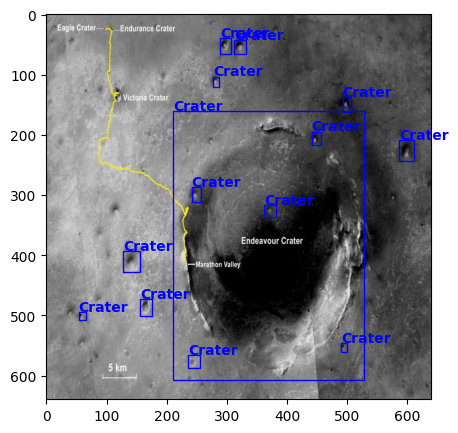

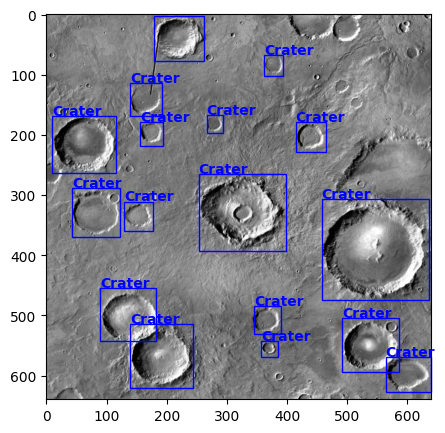

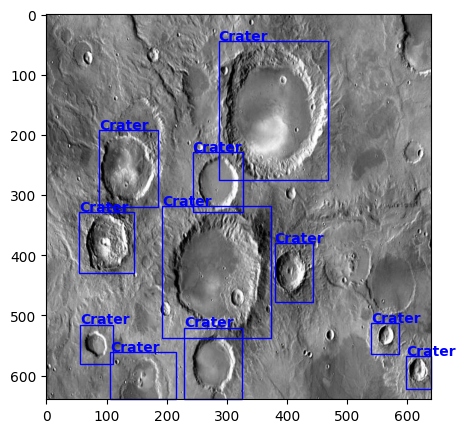

In [17]:
path2train = '/kaggle/input/cv-4-objectdetection/craters/train/'
path2valid = '/kaggle/input/cv-4-objectdetection/craters/valid/'
dataset = CraterDataset(path2train, get_transform(train=True))
# Prints an example of image with annotations
for i in random.sample(range(1, 100), 3):
    img, target = dataset[i]
    plot_img_bbox(img, target)

<a id="Final-train"></a>
# Part 5: Обучение модели, оценка качества предсказаний

In [18]:
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
num_epochs = 10 

# в нашем наборе данных есть только два класса - фон и кратер
num_classes = 2

dataset = CraterDataset(path2train, get_transform(train=True))
dataset_test = CraterDataset(path2valid, get_transform(train=False))


data_loader = torch.utils.data.DataLoader(
        dataset, batch_size=8, shuffle=True, num_workers=2,
    collate_fn=utils.collate_fn)

data_loader_test = torch.utils.data.DataLoader(
    dataset_test, batch_size=1, shuffle=False, num_workers=2,
    collate_fn=utils.collate_fn)

# get the model using our helper function
model = get_model_bbox(num_classes)

'''
Use this to reset all trainable weights
model.apply(reset_weights)
'''

model.to(device)

params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.SGD(params, lr=0.005,  # Feel free to play with values
                            momentum=0.9, weight_decay=0)

# Определение расписания темпов обучения
lr_scheduler = torch.optim.lr_scheduler.StepLR(optimizer,
                                                step_size=20,
                                                gamma=0.2)


result_mAP = []
best_epoch = None

for epoch in range(num_epochs):

    train_one_epoch(model, optimizer, data_loader, device, epoch, print_freq=50)
    # update the learning rate
    lr_scheduler.step()
    # evaluate on the test dataset
    results =  evaluate(model, data_loader_test, device=device)
    # saves results of mAP @ IoU = 0.5
    # result_mAP.append(results.coco_eval['bbox'].stats[1])
    # #save the best model so far
    # if result_mAP[-1] == max(result_mAP):
    #     best_save_path = os.path.join(f'Crater_bestmodel_noaug_sgd(wd=0)_8batch-epoch{epoch}.pth')
    #     torch.save(model.state_dict(), best_save_path)
    #     best_epoch = int(epoch)
    #     print(f'\n\nmodel from epoch number {epoch} saved!\n result is {max(result_mAP)}\n\n')
    
# Saving the last model
save_path = os.path.join(f'model.pth')
torch.save(model.state_dict(), save_path)
print(f'model from last epoch(no.{num_epochs-1}) saved')

/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=FasterRCNN_MobileNet_V3_Large_FPN_Weights.COCO_V1`. You can also use `weights=FasterRCNN_MobileNet_V3_Large_FPN_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/fasterrcnn_mobilenet_v3_large_fpn-fb6a3cc7.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_mobilenet_v3_large_fpn-fb6a3cc7.pth
100%|██████████| 74.2M/74.2M [00:00<00:00, 184MB/s]
/kaggle/working/engine.py:30: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Ple

Epoch: [0]  [ 0/13]  eta: 0:00:26  lr: 0.000421  loss: 1.4468 (1.4468)  loss_classifier: 0.8667 (0.8667)  loss_box_reg: 0.3214 (0.3214)  loss_objectness: 0.2001 (0.2001)  loss_rpn_box_reg: 0.0585 (0.0585)  time: 2.0466  data: 0.2672  max mem: 1783
Epoch: [0]  [12/13]  eta: 0:00:00  lr: 0.005000  loss: 1.0540 (1.1702)  loss_classifier: 0.4553 (0.5099)  loss_box_reg: 0.4193 (0.3948)  loss_objectness: 0.1748 (0.2213)  loss_rpn_box_reg: 0.0419 (0.0442)  time: 0.4484  data: 0.0387  max mem: 1982
Epoch: [0] Total time: 0:00:05 (0.4504 s / it)
creating index...
index created!
Test:  [ 0/26]  eta: 0:00:05  model_time: 0.1004 (0.1004)  evaluator_time: 0.0333 (0.0333)  time: 0.2147  data: 0.0781  max mem: 1982
Test:  [25/26]  eta: 0:00:00  model_time: 0.0264 (0.0290)  evaluator_time: 0.0076 (0.0129)  time: 0.0427  data: 0.0032  max mem: 1982
Test: Total time: 0:00:01 (0.0511 s / it)
Averaged stats: model_time: 0.0264 (0.0290)  evaluator_time: 0.0076 (0.0129)
Accumulating evaluation results...
DO

<a id="Inference"></a>
# Part 7: Inference
Выполняет предсказание обученной моделью отрисовываем обрамлящие рамки для на картинках

In [19]:
dataset_test = CraterDataset(path2valid, get_transform(train=False))

data_loader_test = torch.utils.data.DataLoader(
    dataset_test, batch_size=1, shuffle=False, num_workers=2,
    collate_fn=utils.collate_fn)

model = get_model_bbox(num_classes)

# load model to evaluate
model.load_state_dict(torch.load('model.pth'
                                 ,map_location=device))
model.to(device)

  
evaluate(model, data_loader_test, device=device)

creating index...
index created!
Test:  [ 0/26]  eta: 0:00:03  model_time: 0.0349 (0.0349)  evaluator_time: 0.0122 (0.0122)  time: 0.1308  data: 0.0810  max mem: 1982
Test:  [25/26]  eta: 0:00:00  model_time: 0.0228 (0.0232)  evaluator_time: 0.0019 (0.0047)  time: 0.0324  data: 0.0031  max mem: 1982
Test: Total time: 0:00:00 (0.0372 s / it)
Averaged stats: model_time: 0.0228 (0.0232)  evaluator_time: 0.0019 (0.0047)
Accumulating evaluation results...
DONE (t=0.01s).
IoU metric: bbox
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.165
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.323
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.160
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.079
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.432
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.270
 Average Recall     (AR) @[ IoU=

In [20]:
#Параметры цвета для отрисови рамок
color_inference = np.array([0.0,0.0,255.0])
color_label = np.array([255.0,0.0,0.0])

detection_threshold = 0.2
frame_count = 0

!mkdir ./results

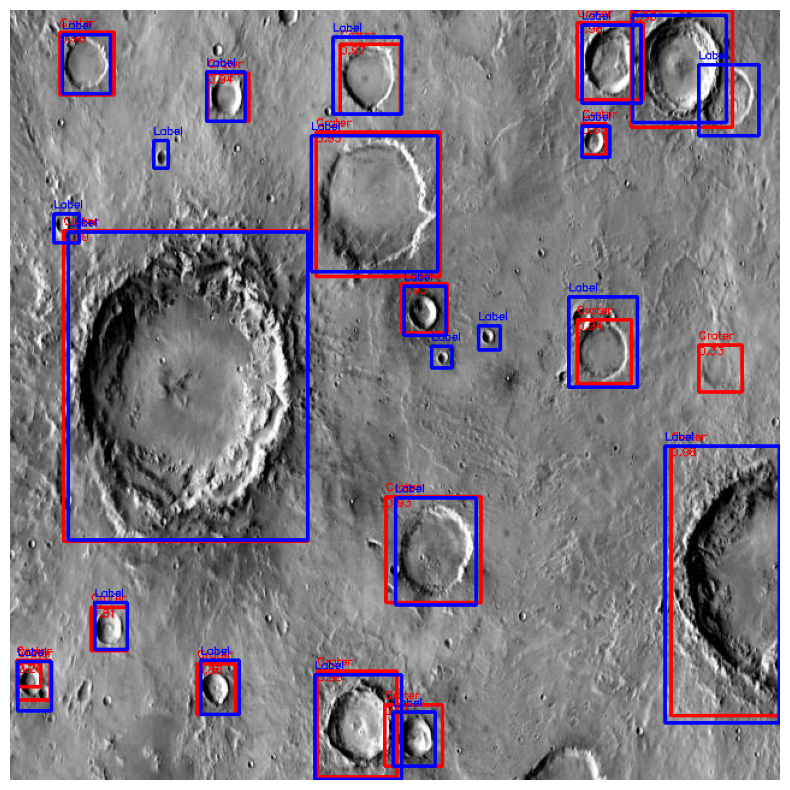

[ WARN:0@81.161] global loadsave.cpp:1063 imwrite_ Unsupported depth image for selected encoder is fallbacked to CV_8U.


Image 1 done...
--------------------------------------------------


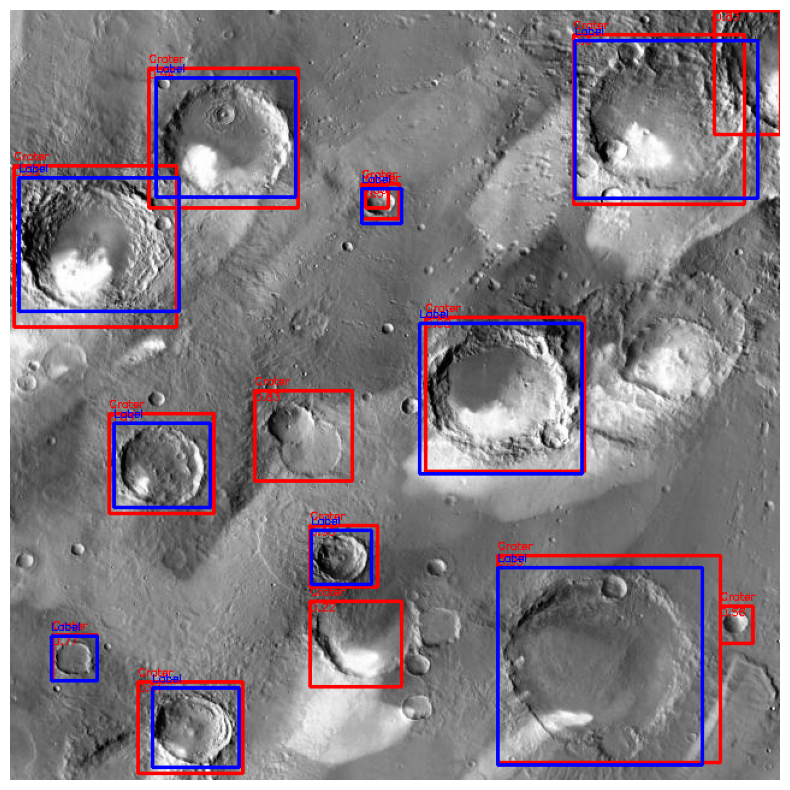

Image 2 done...
--------------------------------------------------


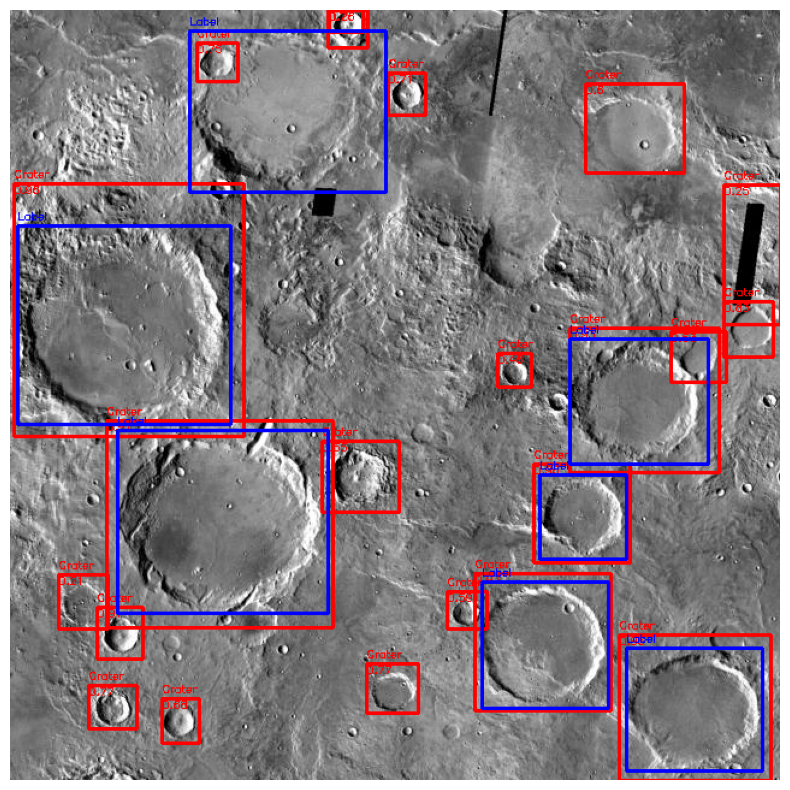

Image 3 done...
--------------------------------------------------


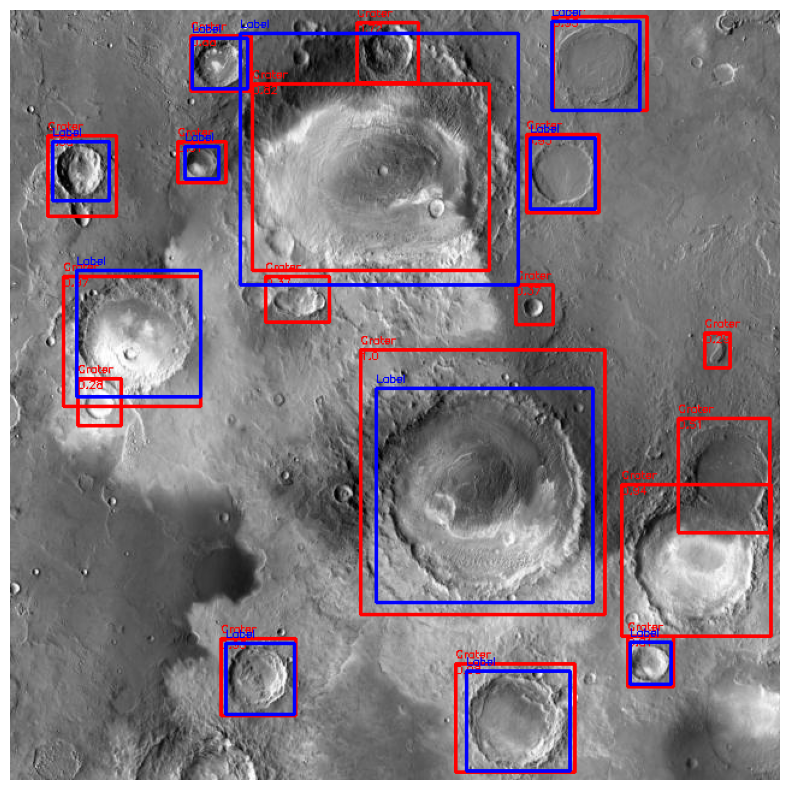

Image 4 done...
--------------------------------------------------


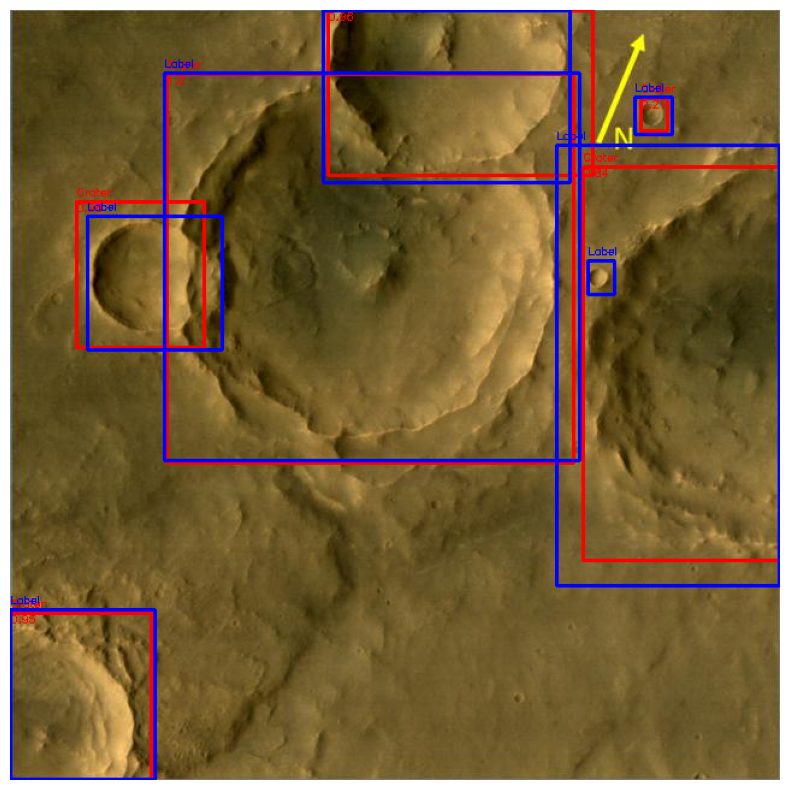

Image 5 done...
--------------------------------------------------


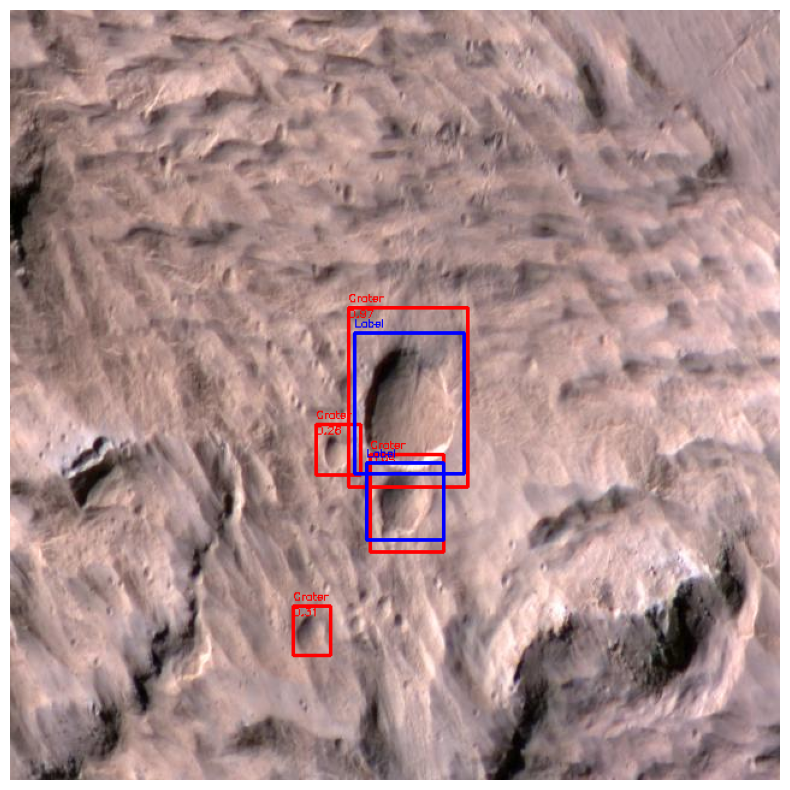

Image 6 done...
--------------------------------------------------


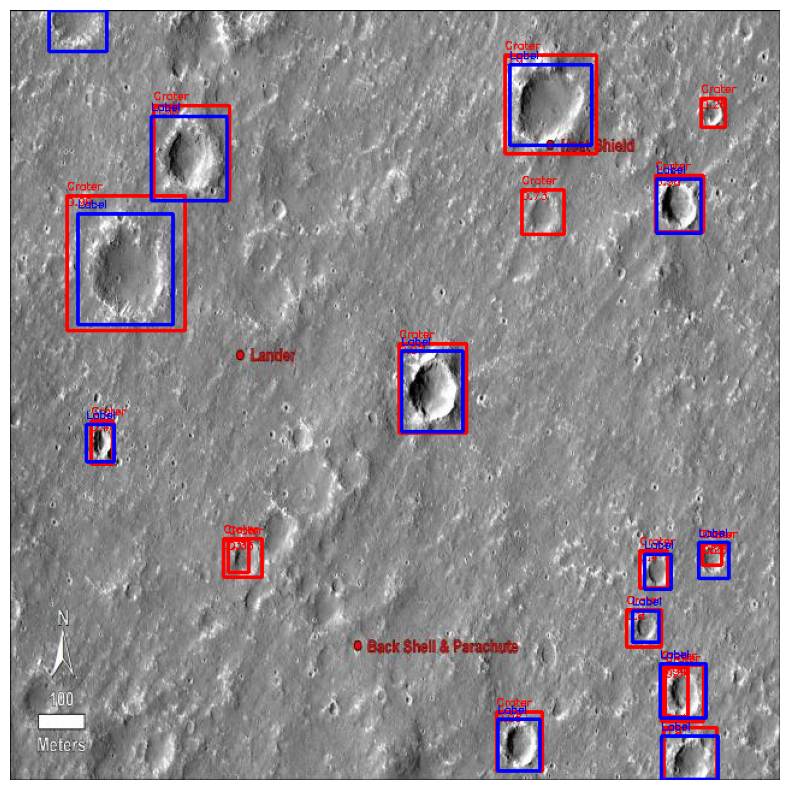

Image 7 done...
--------------------------------------------------


In [21]:
for i,data in enumerate(data_loader_test):
    # считать картики сформировать данные для нейросети
    image_name = 'image no:' + str(int(data[1][0]['image_id']))
    model_image = data[0][0]
    cv2_image = np.transpose(model_image.numpy()*255,(1, 2, 0)).astype(np.float32)
    cv2_image = cv2.cvtColor(cv2_image, cv2.COLOR_RGB2BGR).astype(np.float32)

    # добавить размерность батча
    model_image = torch.unsqueeze(model_image, 0)
    start_time = time.time()
    with torch.no_grad():
        outputs = model(model_image.to(device))
    frame_count += 1
    # перекинуть предсказание с видеокарты на процессор
    outputs = [{k: v.to('cpu') for k, v in t.items()} for t in outputs]
    # проверяем наличие обрамляющих рамок в предсказании
    if len(outputs[0]['boxes']) != 0:
        boxes = outputs[0]['boxes'].data.numpy()
        scores = outputs[0]['scores'].data.numpy()
        # фильтруем предсказания с порогом detection_threshold
        boxes = boxes[scores >= detection_threshold].astype(np.int32)
        scores = np.round(scores[scores >= detection_threshold],2)
        draw_boxes = boxes.copy()

        # рисуем рамки через opencb
        for j,box in enumerate(draw_boxes):
            cv2.rectangle(cv2_image,
                          (int(box[0]), int(box[1])),
                          (int(box[2]), int(box[3])),
                          color_inference, 2)
            cv2.putText(img=cv2_image, text="Crater",
                        org=(int(box[0]), int(box[1] - 5)),
                        fontFace=cv2.FONT_HERSHEY_SIMPLEX,fontScale= 0.3,color= color_inference,
                        thickness=1, lineType=cv2.LINE_AA)
            cv2.putText(img=cv2_image, text=str(scores[j]),
                        org=(int(box[0]), int(box[1] + 8)),
                        fontFace=cv2.FONT_HERSHEY_SIMPLEX,fontScale= 0.3,color= color_inference,
                        thickness=1, lineType=cv2.LINE_AA)
            
        # add boxes for labels
        for box in data[1][0]['boxes']:
            cv2.rectangle(cv2_image,
                          (int(box[0]), int(box[1])),
                          (int(box[2]), int(box[3])),
                          color_label, 2)
            cv2.putText(img=cv2_image, text="Label",
                        org=(int(box[0]), int(box[1] - 5)),
                        fontFace=cv2.FONT_HERSHEY_SIMPLEX,fontScale= 0.3,color= color_label,
                        thickness=1, lineType=cv2.LINE_AA)           
            

        plt.figure(figsize=(10,10))
        plt.axis("off")

        # convert color from CV2 BGR back to RGB
        plt_image = cv2.cvtColor(cv2_image/255.0, cv2.COLOR_BGR2RGB)
        plt.imshow(plt_image)
        plt.show()
        cv2.imwrite(f"./results/{image_name}.jpg", cv2_image)
    print(f"Image {i + 1} done...")
    print('-' * 50)
    if i > 5:
        break

In [22]:
from pathlib import Path
path2test = Path('/kaggle/input/cv-4-objectdetection/craters/test/images')

In [23]:
tranformer = A.Compose([ToTensorV2()])

In [24]:
files = [x for x in path2test.rglob("*")]
f_img = files[0]
source_img = cv2.imread(f_img)
img = cv2.cvtColor(source_img, cv2.COLOR_BGR2RGB).astype(np.float32)
img= img/255.0

model_image = tranformer(image=img)['image']

model_image = torch.unsqueeze(model_image, 0)
outputs = model(model_image.to(device),)


In [25]:

outputs = [{k: v.to('cpu') for k, v in t.items()} for t in outputs]

if len(outputs[0]['boxes']) != 0:
    boxes = outputs[0]['boxes'].data.numpy()
    scores = outputs[0]['scores'].data.numpy()
    # отфильтровать предсказания 'detection_threshold`
    boxes = boxes[scores >= detection_threshold].astype(np.int32)
    scores = np.round(scores[scores >= detection_threshold],2)
    draw_boxes = boxes.copy()

In [26]:
masks = []
detection_threshold = 0.2
for f_img in path2test.glob("*.jpg"):
    source_img = cv2.imread(f_img)
    w, h, _ = source_img.shape
    ans = np.zeros((w,h))
    img = cv2.cvtColor(source_img, cv2.COLOR_BGR2RGB).astype(np.float32)
    img= img/255.0
    
    model_image = tranformer(image=img)['image']
    
    model_image = torch.unsqueeze(model_image, 0)
    outputs = model(model_image.to(device),)

    outputs = [{k: v.to('cpu') for k, v in t.items()} for t in outputs]
    if len(outputs[0]['boxes']) != 0:
        boxes = outputs[0]['boxes'].data.numpy()
        scores = outputs[0]['scores'].data.numpy()
        boxes = boxes[scores >= detection_threshold].astype(np.int32)
        scores = np.round(scores[scores >= detection_threshold],2)
        draw_boxes = boxes.copy()
        for box in draw_boxes:
            x1,y1, x2, y2 = box
            ans[y1:y2, x1:x2] = 1
    masks.append((f_img.name,img,ans))

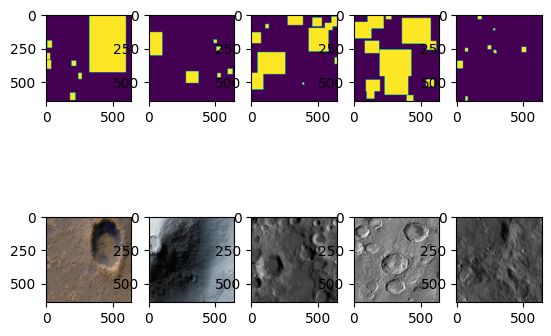

In [27]:
fig, ax = plt.subplots(2,5)
for i in range(5):
    name, img, mask = masks[i]
    ax[0][i].imshow(mask)
    ax[1][i].imshow(img)

<a id="Inference. Формирование файла предсказаний"></a>
# Часть 7: Inference. Формирование файла предсказаний
Выполняем предсказание обученной моделью. Заполняем области внутри обмамляющих рамок значение "1", остальное "0". Результаты предсказаний 
кодируем rle формат и записываем в 'csv'. 

In [28]:
def rle_encode_tensor(mask_tensor):
    """
    Encode a PyTorch binary mask tensor into Kaggle-style RLE string.

    Args:
        mask_tensor: torch.Tensor of shape (H, W) or (1, H, W)
                     dtype: bool, int, or float (will be thresholded at 0.5 if float)

    Returns:
        str: RLE string (e.g., "1 3 10 5 ...") or empty string if no foreground
    """
    # Убираем лишние измерения
    if mask_tensor.ndim == 3:
        if mask_tensor.shape[0] == 1:
            mask_tensor = mask_tensor.squeeze(0)
        else:
            raise ValueError("Expected single-channel mask, got shape: {}".format(mask_tensor.shape))

    # Переводим на CPU и в numpy
    mask = mask_tensor.detach().cpu().numpy()

    # Бинаризуем, если нужно
    if mask.dtype == np.float32 or mask.dtype == np.float64:
        mask = mask > 0.5
    else:
        mask = mask.astype(bool)

    # Проверка на пустую маску
    if mask.sum() == 0:
        return ""

    # RLE в column-major порядке (Kaggle стандарт)
    pixels = mask.T.flatten()  # <-- ВАЖНО: .T для column-major
    pixels = np.concatenate([[0], pixels, [0]])  # паддинг
    runs = np.where(pixels[1:] != pixels[:-1])[0] + 1
    runs[1::2] -= runs[::2]

    return ' '.join(str(x) for x in runs)

In [29]:
ious = []
all_masks = []
for f, img, mask in masks:
    rle_code = rle_encode_tensor(torch.tensor(mask))
    all_masks.append({"FILE_NAME":f,
          "TARGET": rle_code})

In [30]:
frame = pd.DataFrame(all_masks).sort_values('FILE_NAME')
frame.to_csv('submission.csv', index = False)

In [31]:
frame.head()

,FILE_NAME,TARGET
22,010_png.rf.fcf5e274562ee69a325f9d7a0b30767f.jpg,501 97 1141 97 1781 97 2421 97 3061 97 3701 97...
3,015_png.rf.7d5b2091b6339c9480a171a59c52c3b9.jpg,2612 124 3252 124 3892 124 4532 124 5172 124 5...
29,019_png.rf.1930cd277f9bf0e3fa57f2dcfee0385f.jpg,1446 176 2086 176 2726 176 3366 176 4006 176 4...
5,04_png.rf.81a7d6cbeb9dc09e5a8ecd40e185fc92.jpg,13372 46 14012 46 14652 46 15292 46 15932 46 1...
23,Lunar_A_0-0_png_jpg.rf.74e92e6bd5b9fbe3cae163f...,9614 130 10254 130 10579 162 10894 130 11219 1...


## Добавьте в ноутбук отдельный раздел «Анализ результатов работы модели», включающий следующие пункты:

Проведите не менее трёх экспериментов с разными гиперпараметрами (например, learning rate, размер батча, эпохи, разморозка слоев архитектуры). Составьте таблицу результатов. На основе метрик выберите наилучший вариант для финального обучения. Для финальной модели выполните детальный анализ результатов:

a) Анализ по размеру объектов — разбейте результаты на три категории: Small, Medium, Large (в соответствии со стандартом COCO). Оцените, насколько хорошо модель справляется с объектами разного размера. Особое внимание уделите маленьким кратерам? (5 баллов)

b) Влияние порога уверенности (confidence threshold) — проанализируйте, как изменение порога уверенности влияет на точность метрику Постройте график dice зависимости от порога. (5 баллов)

c) Визуализация результатов — приведите примеры: Успешных предсказаний (точное совпадение маски и положения кратера); Типичных ошибок (ложные срабатывания, пропущенные кратеры, неточные маски). Для каждого примера поясните возможную причину ошибки. (5 баллов)